Shape: (5025, 17)
            State  Year       Crop  Season Soil_Type  Area_ha  Rainfall_mm  \
0     West Bengal  2014    Soybean  Kharif  Laterite  26069.8       1207.0   
1       Telangana  2022  Groundnut  Kharif       Red  24887.1        853.5   
2         Gujarat  2021     Cotton  Kharif     Black   1610.1        387.1   
3  Andhra Pradesh  2007    Soybean  Kharif  Alluvial   4342.8        974.3   
4       Telangana  2023     Cotton  Kharif       Red  44521.7       1107.2   

   Avg_Temp_C  Humidity_pct  Soil_pH  Nitrogen_kg_ha  Phosphorus_kg_ha  \
0        26.8          81.9     6.55            25.8              43.9   
1        29.3          57.2     6.81            26.5              91.4   
2        26.3          52.8     7.63           136.6              24.5   
3        30.0          69.1     6.03            27.1              37.7   
4        30.0          72.0     6.94             5.0              37.7   

   Potassium_kg_ha  Irrigation_pct  Pesticide_kg_ha  Yield_t_ha  Pro

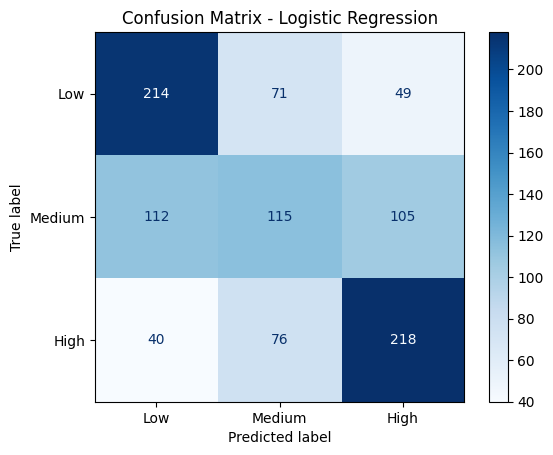

In [8]:
# ============================================================
# Member 1: Logistic Regression
# Dataset : India Crop Yield Dataset (india_crop_yield.csv)
# Task    : Classify yield as Low / Medium / High
# ============================================================
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings("ignore")

# ---------------- 1. Load dataset ----------------

path = (glob.glob("/kaggle/input/**/india_crop_yield.csv", recursive=True) + glob.glob("india_crop_yield.csv"))[0]
df = pd.read_csv(path)
print("Shape:", df.shape)+
print(df.head())
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

# ---------------- 2. Pre-processing ----------------
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))
df["Yield_Class"] = df.groupby("Crop")["Yield_t_ha"].transform(
    lambda s: pd.qcut(s, 3, labels=["Low", "Medium", "High"])).astype(str)
print("\nClass counts:\n", df["Yield_Class"].value_counts())

data = df.drop(columns=["Yield_t_ha", "Production_t"])
data = pd.get_dummies(data, columns=["State", "Crop", "Season", "Soil_Type"], drop_first=True)
X = data.drop(columns=["Yield_Class"])
y = data["Yield_Class"]

# ---------------- 3. Train-test split ----------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Feature scaling (required for Logistic Regression)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# ---------------- 4. Train model ----------------
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

# ---------------- 5. Predict & evaluate ----------------
y_pred = model.predict(X_test)
labels = ["Low", "Medium", "High"]
print("\n===== Logistic Regression =====")
print("Train Accuracy:", round(accuracy_score(y_train, model.predict(X_train)), 4))
print("Test Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=labels, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels),
                       display_labels=labels).plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression"); plt.show()

Shape: (5025, 17)
            State  Year       Crop  Season Soil_Type  Area_ha  Rainfall_mm  \
0     West Bengal  2014    Soybean  Kharif  Laterite  26069.8       1207.0   
1       Telangana  2022  Groundnut  Kharif       Red  24887.1        853.5   
2         Gujarat  2021     Cotton  Kharif     Black   1610.1        387.1   
3  Andhra Pradesh  2007    Soybean  Kharif  Alluvial   4342.8        974.3   
4       Telangana  2023     Cotton  Kharif       Red  44521.7       1107.2   

   Avg_Temp_C  Humidity_pct  Soil_pH  Nitrogen_kg_ha  Phosphorus_kg_ha  \
0        26.8          81.9     6.55            25.8              43.9   
1        29.3          57.2     6.81            26.5              91.4   
2        26.3          52.8     7.63           136.6              24.5   
3        30.0          69.1     6.03            27.1              37.7   
4        30.0          72.0     6.94             5.0              37.7   

   Potassium_kg_ha  Irrigation_pct  Pesticide_kg_ha  Yield_t_ha  Pro

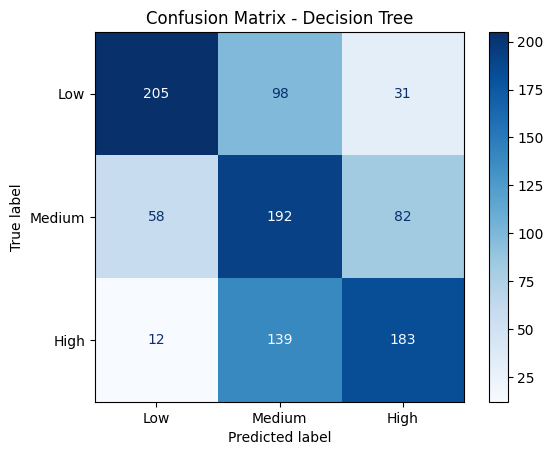


Top 10 features:
 Rainfall_mm       0.2534
Soil_pH           0.1926
Avg_Temp_C        0.1178
Irrigation_pct    0.1174
Nitrogen_kg_ha    0.0472
Season_Rabi       0.0458
Year              0.0432
Soil_Type_Arid    0.0370
Humidity_pct      0.0249
Crop_Rice         0.0207
dtype: float64


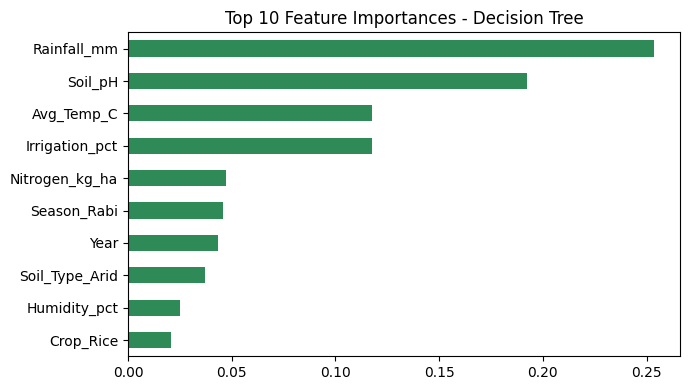

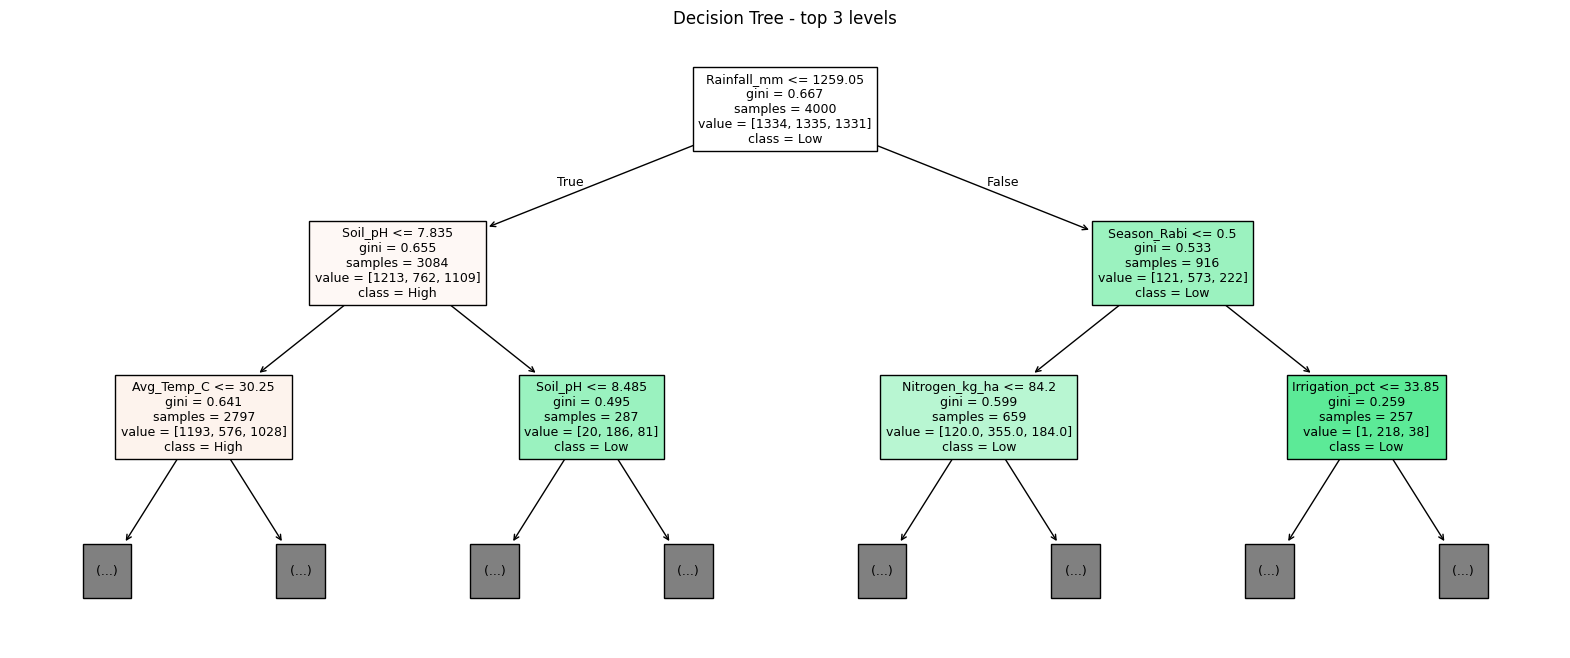

In [9]:
# ============================================================
# Member 2: Decision Tree
# Dataset : India Crop Yield Dataset (india_crop_yield.csv)
# Task    : Classify yield as Low / Medium / High
# ============================================================
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier, plot_tree
warnings.filterwarnings("ignore")

# ---------------- 1. Load dataset ----------------
path = (glob.glob("/kaggle/input/**/india_crop_yield.csv", recursive=True) + glob.glob("india_crop_yield.csv"))[0]
df = pd.read_csv(path)
print("Shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

# ---------------- 2. Pre-processing ----------------
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))
df["Yield_Class"] = df.groupby("Crop")["Yield_t_ha"].transform(
    lambda s: pd.qcut(s, 3, labels=["Low", "Medium", "High"])).astype(str)
print("\nClass counts:\n", df["Yield_Class"].value_counts())

data = df.drop(columns=["Yield_t_ha", "Production_t"])
data = pd.get_dummies(data, columns=["State", "Crop", "Season", "Soil_Type"], drop_first=True)
X = data.drop(columns=["Yield_Class"])
y = data["Yield_Class"]

# ---------------- 3. Train-test split ----------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

# ---------------- 4. Train model ----------------
model = DecisionTreeClassifier(criterion="gini", max_depth=8, random_state=42)
model.fit(X_train, y_train)
print("Depth:", model.get_depth(), "| Leaves:", model.get_n_leaves())

# ---------------- 5. Predict & evaluate ----------------
y_pred = model.predict(X_test)
labels = ["Low", "Medium", "High"]
print("\n===== Decision Tree =====")
print("Train Accuracy:", round(accuracy_score(y_train, model.predict(X_train)), 4))
print("Test Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=labels, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels),
                       display_labels=labels).plot(cmap="Blues")
plt.title("Confusion Matrix - Decision Tree"); plt.show()

# ---------------- 6. Feature importance ----------------
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
print("\nTop 10 features:\n", imp.round(4))
imp[::-1].plot.barh(color="seagreen", figsize=(7, 4))
plt.title("Top 10 Feature Importances - Decision Tree"); plt.tight_layout(); plt.show()

# ---------------- 7. Tree diagram ----------------
plt.figure(figsize=(20, 8))
plot_tree(model, max_depth=2, feature_names=list(X.columns), class_names=list(model.classes_),
          filled=True, fontsize=9)
plt.title("Decision Tree - top 3 levels"); plt.show()

Shape: (5025, 17)
            State  Year       Crop  Season Soil_Type  Area_ha  Rainfall_mm  \
0     West Bengal  2014    Soybean  Kharif  Laterite  26069.8       1207.0   
1       Telangana  2022  Groundnut  Kharif       Red  24887.1        853.5   
2         Gujarat  2021     Cotton  Kharif     Black   1610.1        387.1   
3  Andhra Pradesh  2007    Soybean  Kharif  Alluvial   4342.8        974.3   
4       Telangana  2023     Cotton  Kharif       Red  44521.7       1107.2   

   Avg_Temp_C  Humidity_pct  Soil_pH  Nitrogen_kg_ha  Phosphorus_kg_ha  \
0        26.8          81.9     6.55            25.8              43.9   
1        29.3          57.2     6.81            26.5              91.4   
2        26.3          52.8     7.63           136.6              24.5   
3        30.0          69.1     6.03            27.1              37.7   
4        30.0          72.0     6.94             5.0              37.7   

   Potassium_kg_ha  Irrigation_pct  Pesticide_kg_ha  Yield_t_ha  Pro

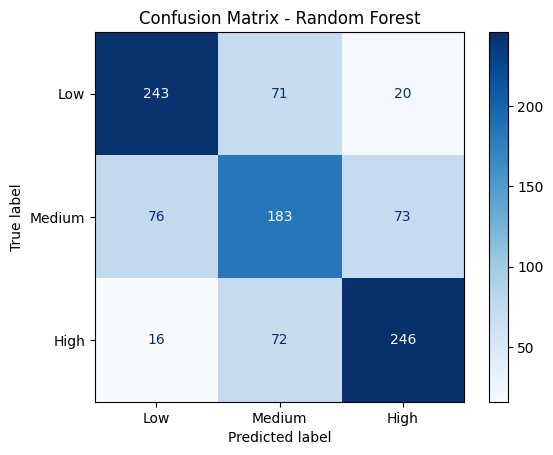


Top 10 features:
 Rainfall_mm         0.1201
Soil_pH             0.1108
Avg_Temp_C          0.0923
Humidity_pct        0.0740
Irrigation_pct      0.0729
Nitrogen_kg_ha      0.0653
Area_ha             0.0551
Potassium_kg_ha     0.0550
Phosphorus_kg_ha    0.0536
Pesticide_kg_ha     0.0534
dtype: float64


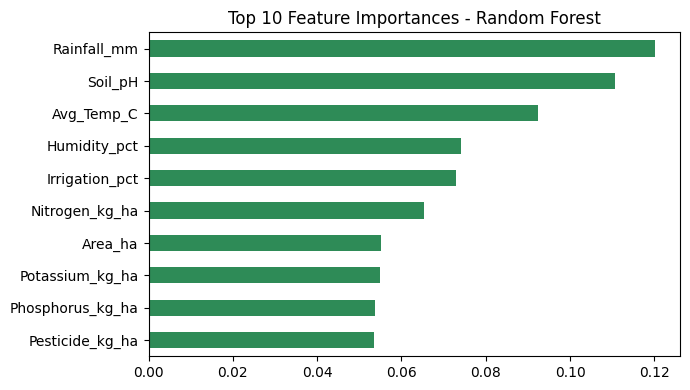

In [10]:
# ============================================================
# Member 3: Random Forest
# Dataset : India Crop Yield Dataset (india_crop_yield.csv)
# Task    : Classify yield as Low / Medium / High
# ============================================================
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")

# ---------------- 1. Load dataset ----------------
path = (glob.glob("/kaggle/input/**/india_crop_yield.csv", recursive=True) + glob.glob("india_crop_yield.csv"))[0]
df = pd.read_csv(path)
print("Shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

# ---------------- 2. Pre-processing ----------------
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))
df["Yield_Class"] = df.groupby("Crop")["Yield_t_ha"].transform(
    lambda s: pd.qcut(s, 3, labels=["Low", "Medium", "High"])).astype(str)
print("\nClass counts:\n", df["Yield_Class"].value_counts())

data = df.drop(columns=["Yield_t_ha", "Production_t"])
data = pd.get_dummies(data, columns=["State", "Crop", "Season", "Soil_Type"], drop_first=True)
X = data.drop(columns=["Yield_Class"])
y = data["Yield_Class"]

# ---------------- 3. Train-test split ----------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

# ---------------- 4. Train model ----------------
model = RandomForestClassifier(n_estimators=300, random_state=42)
model.fit(X_train, y_train)

# ---------------- 5. Predict & evaluate ----------------
y_pred = model.predict(X_test)
labels = ["Low", "Medium", "High"]
print("\n===== Random Forest =====")
print("Train Accuracy:", round(accuracy_score(y_train, model.predict(X_train)), 4))
print("Test Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=labels, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels),
                       display_labels=labels).plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest"); plt.show()

# ---------------- 6. Feature importance ----------------
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
print("\nTop 10 features:\n", imp.round(4))
imp[::-1].plot.barh(color="seagreen", figsize=(7, 4))
plt.title("Top 10 Feature Importances - Random Forest"); plt.tight_layout(); plt.show()

Shape: (5025, 17)
            State  Year       Crop  Season Soil_Type  Area_ha  Rainfall_mm  \
0     West Bengal  2014    Soybean  Kharif  Laterite  26069.8       1207.0   
1       Telangana  2022  Groundnut  Kharif       Red  24887.1        853.5   
2         Gujarat  2021     Cotton  Kharif     Black   1610.1        387.1   
3  Andhra Pradesh  2007    Soybean  Kharif  Alluvial   4342.8        974.3   
4       Telangana  2023     Cotton  Kharif       Red  44521.7       1107.2   

   Avg_Temp_C  Humidity_pct  Soil_pH  Nitrogen_kg_ha  Phosphorus_kg_ha  \
0        26.8          81.9     6.55            25.8              43.9   
1        29.3          57.2     6.81            26.5              91.4   
2        26.3          52.8     7.63           136.6              24.5   
3        30.0          69.1     6.03            27.1              37.7   
4        30.0          72.0     6.94             5.0              37.7   

   Potassium_kg_ha  Irrigation_pct  Pesticide_kg_ha  Yield_t_ha  Pro

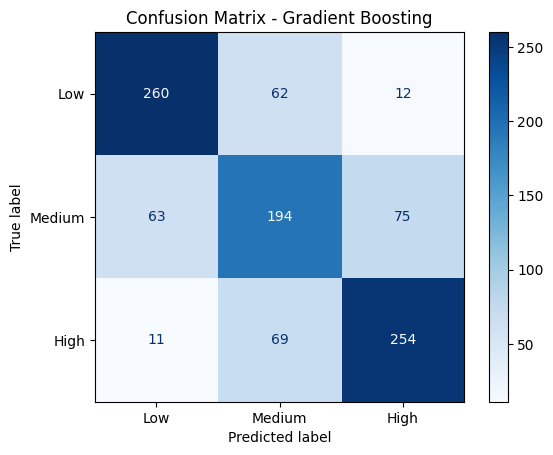


Top 10 features:
 Rainfall_mm       0.2039
Soil_pH           0.1778
Avg_Temp_C        0.1531
Irrigation_pct    0.0972
Nitrogen_kg_ha    0.0643
Year              0.0322
Season_Rabi       0.0297
Humidity_pct      0.0294
Crop_Rice         0.0237
Area_ha           0.0220
dtype: float64


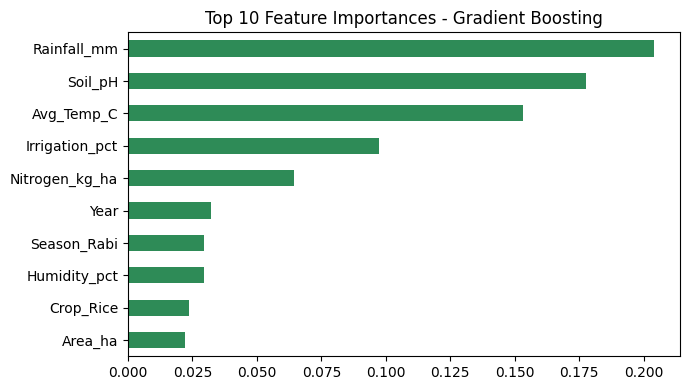

In [11]:
# ============================================================
# Member 4: Gradient Boosting
# Dataset : India Crop Yield Dataset (india_crop_yield.csv)
# Task    : Classify yield as Low / Medium / High
# ============================================================
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import GradientBoostingClassifier
warnings.filterwarnings("ignore")

# ---------------- 1. Load dataset ----------------
path = (glob.glob("/kaggle/input/**/india_crop_yield.csv", recursive=True) + glob.glob("india_crop_yield.csv"))[0]
df = pd.read_csv(path)
print("Shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())

# ---------------- 2. Pre-processing ----------------
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))
df["Yield_Class"] = df.groupby("Crop")["Yield_t_ha"].transform(
    lambda s: pd.qcut(s, 3, labels=["Low", "Medium", "High"])).astype(str)
print("\nClass counts:\n", df["Yield_Class"].value_counts())

data = df.drop(columns=["Yield_t_ha", "Production_t"])
data = pd.get_dummies(data, columns=["State", "Crop", "Season", "Soil_Type"], drop_first=True)
X = data.drop(columns=["Yield_Class"])
y = data["Yield_Class"]

# ---------------- 3. Train-test split ----------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

# ---------------- 4. Train model ----------------
model = GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42)
model.fit(X_train, y_train)

# ---------------- 5. Predict & evaluate ----------------
y_pred = model.predict(X_test)
labels = ["Low", "Medium", "High"]
print("\n===== Gradient Boosting =====")
print("Train Accuracy:", round(accuracy_score(y_train, model.predict(X_train)), 4))
print("Test Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=labels, digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels),
                       display_labels=labels).plot(cmap="Blues")
plt.title("Confusion Matrix - Gradient Boosting"); plt.show()

# ---------------- 6. Feature importance ----------------
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
print("\nTop 10 features:\n", imp.round(4))
imp[::-1].plot.barh(color="seagreen", figsize=(7, 4))
plt.title("Top 10 Feature Importances - Gradient Boosting"); plt.tight_layout(); plt.show()